<a href="https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X4c_complexos_edo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# Domínio IV (c): o pêndulo de Foucault

## Referenciais que giram em notação complexa, a Terra que gira debaixo do pêndulo, e o Runge–Kutta que sai do círculo

**Série:** [raiz](X0_raiz.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X0_raiz.ipynb)) · **Domínio:** [nó 4](X4_complexos.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X4_complexos.ipynb)) · **Anterior:** [X4b_complexos_sistemas.ipynb](X4b_complexos_sistemas.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X4b_complexos_sistemas.ipynb)) · **Próximo:** [X4d_complexos_perseguicao.ipynb](X4d_complexos_perseguicao.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X4d_complexos_perseguicao.ipynb))

**Objetivo.** Usar a notação complexa para o movimento no plano com **rotação**:
- num **referencial que gira**, as forças de Coriolis e centrífuga aparecem numa linha, derivando um produto por $e^{i\Omega t}$;
- o **pêndulo de Foucault** (Panthéon, Paris, 1851): o plano de oscilação de um pêndulo longo gira lentamente, porque é a Terra que gira debaixo dele. Em notação complexa, a equação do movimento é uma única EDO linear, e o `sympy` resolve;
- **integrar uma rotação:** a orientação de um corpo no plano é um complexo unitário $q(t)$, com $\dot q=i\omega(t)\,q$. O Runge–Kutta clássico **sai do círculo** ($\lvert q\rvert$ deixa de ser 1); o RKMK, que avança por multiplicação, não sai. No domínio III, com o ângulo como estado, os dois eram iguais; com o complexo como estado, deixam de ser.

No fim, como sempre, as matrizes do filtro da etapa (d): a orientação de Pepé, com um giroscópio que tem viés.

**Roteiro**
1. Rotação no tempo: $z(t)=e^{i\omega t}z_0$
2. Referenciais que giram: Coriolis e centrífuga numa linha
3. O pêndulo de Foucault: a equação, a solução e a precessão
4. Foucault numérico: RK4 complexo e a medida da precessão
5. Integrar uma orientação: RK4 sai do círculo, RKMK não
6. Espaço de estados para a etapa (d)
7. Exercícios

In [1]:
# Ferramentas comuns da série (repetidas em todos os notebooks, para que cada um rode sozinho no Colab)
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 100,
                     "axes.spines.top": False, "axes.spines.right": False})

def confere(nome, obtido, esperado, tol=1e-9, relativo=False):
    """Compara duas quantidades. Imprime OK ou interrompe o notebook com uma mensagem clara."""
    a, b = np.asarray(obtido), np.asarray(esperado)
    tipo = complex if (np.iscomplexobj(a) or np.iscomplexobj(b)) else float      # aceita complexos (domínio IV)
    a, b = a.astype(tipo), b.astype(tipo)
    escala = max(np.max(np.abs(b)), 1e-300) if relativo else 1.0
    erro = float(np.max(np.abs(a - b)) / escala)
    ok = erro <= tol
    print(f"{'OK ' if ok else 'FALHOU'}  {nome}:  diferença {'relativa ' if relativo else ''}máxima = {erro:.2e}")
    assert ok, f"conferência falhou: {nome}"

import sympy as sp
from scipy.linalg import expm
rng = np.random.default_rng(43)

def rk4(f, y0, T, h):
    y = y0
    for i in range(int(round(T / h))):
        t = i * h
        k1 = f(t, y); k2 = f(t + h / 2, y + h / 2 * k1); k3 = f(t + h / 2, y + h / 2 * k2); k4 = f(t + h, y + h * k3)
        y = y + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
    return y

---

## 1. Rotação no tempo

Um ponto que gira em torno da origem com velocidade angular constante $\omega$ está em $z(t)=e^{i\omega t}z_0$. Derivar em relação ao tempo é multiplicar por $i\omega$:

$$\dot z=i\omega\,z,\qquad \ddot z=-\omega^2z .$$

Multiplicar por $i$ é girar de 90°: a velocidade é **perpendicular** à posição, com módulo $\omega\lvert z\rvert$, e a aceleração aponta para o centro, com módulo $\omega^2\lvert z\rvert$ (a aceleração centrípeta). Em coordenadas reais, isso exigiria senos, cossenos e um pouco de trigonometria; em notação complexa, é a regra da cadeia.

In [2]:
t, w, r0 = sp.symbols("t omega r_0", positive=True)
z = r0 * sp.exp(sp.I * w * t)
print("ż / z =", sp.simplify(z.diff(t) / z), ";   z̈ / z =", sp.simplify(z.diff(t, 2) / z))
print("|ż| =", sp.simplify(sp.Abs(z.diff(t))), ";   ż · z̄ (o produto escalar é a parte real) =", sp.simplify(sp.re(sp.expand(z.diff(t) * sp.conjugate(z)))))

ż / z = I*omega ;   z̈ / z = -omega**2
|ż| = omega*r_0 ;   ż · z̄ (o produto escalar é a parte real) = 0


---

## 2. Referenciais que giram

Um observador num carrossel (ou na Terra) usa coordenadas que giram com velocidade angular $\Omega$. Se $z$ é a posição num referencial **fixo** e $z_r$ a posição medida pelo observador que gira, então $z=e^{i\Omega t}z_r$. Derivando duas vezes, pela regra do produto:

$$\ddot z=e^{i\Omega t}\Big(\ddot z_r+2i\Omega\,\dot z_r-\Omega^2z_r\Big).$$

Se no referencial fixo a força por unidade de massa é $a$, então $\ddot z=a$, e o observador que gira vê

$$\ddot z_r=e^{-i\Omega t}a\;\underbrace{-\,2i\Omega\,\dot z_r}_{\text{Coriolis}}\;\underbrace{+\,\Omega^2z_r}_{\text{centrífuga}} .$$

As duas "forças fictícias" saíram de uma linha de derivação. A de Coriolis é **perpendicular** à velocidade (o fator $i$), e não realiza trabalho: só desvia. Com $\Omega>0$ (giro anti-horário), ela desvia para a direita.

In [3]:
Om = sp.Symbol("Omega", positive=True)
zr = sp.Function("z_r")(t)
z_fixo = sp.exp(sp.I * Om * t) * zr
print("e^{−iΩt} z̈ =", sp.expand(sp.simplify(sp.exp(-sp.I * Om * t) * z_fixo.diff(t, 2))))

e^{−iΩt} z̈ = -Omega**2*z_r(t) + 2*I*Omega*Derivative(z_r(t), t) + Derivative(z_r(t), (t, 2))


---

## 3. O pêndulo de Foucault

**A montagem.** Um pêndulo longo (no Panthéon, um fio de 67 m e uma bola de 28 kg) oscila com pequena amplitude. Seja $z=x+iy$ a posição horizontal da bola, com $x$ para o leste e $y$ para o norte. Sem a rotação da Terra, cada coordenada seria um oscilador harmônico, $\ddot z=-\omega_0^2z$, com $\omega_0=\sqrt{g/L}$.

**A rotação da Terra.** A Terra gira com $\Omega=7{,}292\times10^{-5}$ rad/s (uma volta por dia sideral, 23 h 56 min). Num lugar de latitude $\lambda$, só a componente **vertical** dessa rotação, $\Omega_z=\Omega\sin\lambda$, afeta o movimento horizontal: o chão gira em torno da vertical local com velocidade $\Omega_z$. Pela seção 2 (desprezando a força centrífuga, que só muda um pouco a direção da vertical e o valor de $g$), a equação do pêndulo no referencial do chão é

$$\ddot z+2i\Omega_z\,\dot z+\omega_0^2\,z=0 .$$

Uma EDO linear de segunda ordem, com coeficientes complexos constantes. As raízes da equação característica, $r^2+2i\Omega_zr+\omega_0^2=0$, são $r=-i\Omega_z\pm i\sqrt{\omega_0^2+\Omega_z^2}$, e a solução é

$$z(t)=e^{-i\Omega_zt}\Big(A\,e^{i\omega t}+B\,e^{-i\omega t}\Big),\qquad\omega=\sqrt{\omega_0^2+\Omega_z^2}.$$

O termo entre parênteses é uma oscilação comum, num plano fixo (com $A=B$, uma reta). O fator $e^{-i\Omega_zt}$ **gira** esse plano com velocidade $-\Omega_z$. Tudo que se precisa é de uma multiplicação.

In [4]:
Oz, w0 = sp.symbols("Omega_z omega_0", positive=True)
zt = sp.Function("z")(t)
sol = sp.dsolve(zt.diff(t, 2) + 2 * sp.I * Oz * zt.diff(t) + w0**2 * zt, zt)
print("solução geral:", sol.rhs)
r = sp.Symbol("r")
print("raízes características:", sp.solve(r**2 + 2 * sp.I * Oz * r + w0**2, r))

# período da precessão: 2π/Ω_z = (dia sideral)/sen λ
OMEGA = 7.2921159e-5
dia_sideral_h = 2 * np.pi / OMEGA / 3600
print(f"\ndia sideral = {dia_sideral_h:.3f} h")
for nome, lat in [("polo norte", 90.0), ("Paris (Panthéon)", 48.846), ("20° N", 20.0), ("equador", 0.0), ("20° S", -20.0), ("polo sul", -90.0)]:
    Oz_ = OMEGA * np.sin(np.radians(lat))
    sentido = "horário" if Oz_ > 0 else ("anti-horário" if Oz_ < 0 else "não gira")
    periodo = f"{2 * np.pi / abs(Oz_) / 3600:6.1f} h" if Oz_ != 0 else "    ∞  "
    print(f"{nome:18s} λ = {lat:+7.2f}°   o plano dá uma volta em {periodo}, no sentido {sentido} (visto de cima)")
confere("Paris: uma volta em ≈ 31,8 h", 2 * np.pi / (OMEGA * np.sin(np.radians(48.846))) / 3600, 31.8, tol=0.05)

solução geral: C1*exp(I*t*(-Omega_z + sqrt(Omega_z**2 + omega_0**2))) + C2*exp(-I*t*(Omega_z + sqrt(Omega_z**2 + omega_0**2)))
raízes características: [I*(-Omega_z - sqrt(Omega_z**2 + omega_0**2)), I*(-Omega_z + sqrt(Omega_z**2 + omega_0**2))]

dia sideral = 23.934 h
polo norte         λ =  +90.00°   o plano dá uma volta em   23.9 h, no sentido horário (visto de cima)
Paris (Panthéon)   λ =  +48.85°   o plano dá uma volta em   31.8 h, no sentido horário (visto de cima)
20° N              λ =  +20.00°   o plano dá uma volta em   70.0 h, no sentido horário (visto de cima)
equador            λ =   +0.00°   o plano dá uma volta em     ∞  , no sentido não gira (visto de cima)
20° S              λ =  -20.00°   o plano dá uma volta em   70.0 h, no sentido anti-horário (visto de cima)
polo sul           λ =  -90.00°   o plano dá uma volta em   23.9 h, no sentido anti-horário (visto de cima)
OK   Paris: uma volta em ≈ 31,8 h:  diferença máxima = 1.21e-02


**Leitura.** No polo, o plano de oscilação dá uma volta por dia sideral: o pêndulo fica parado no espaço, e a Terra gira inteira debaixo dele. Em Paris, o período é de quase 32 horas; a 20° de latitude, mais de 70 horas; no equador, o plano não gira. No **hemisfério sul**, $\sin\lambda<0$, e o plano gira no sentido **anti-horário**, o contrário do de Paris. É um dos experimentos mais diretos que mostram que a Terra gira, sem olhar para o céu.

---

## 4. Foucault numérico: RK4 complexo e a medida da precessão

O RK4 funciona com estados complexos sem mudar uma linha: o estado é o par $(z,\dot z)$, um vetor de dois complexos, e o NumPy faz as contas. A célula integra o pêndulo do Panthéon ($L=67$ m) por **uma hora**, solto a 3 m para leste, e mede o ângulo do plano de oscilação no fim. A medida usa a forma da trajetória nas últimas cinco oscilações: a direção do eixo maior da nuvem de pontos (o autovetor principal da covariância das posições), que é a direção do plano. Como a medida é uma média sobre esse trecho, a previsão é $-\Omega_zt$ no **meio** dele (uns 40 s antes do fim), no sentido horário em Paris.

In [5]:
G, L_FIO = 9.81, 67.0
W0 = np.sqrt(G / L_FIO)
LAT = np.radians(48.846)
OZ = OMEGA * np.sin(LAT)
print(f"período do pêndulo: {2 * np.pi / W0:.2f} s")

def f_foucault(t, s, Oz=OZ):
    z, v = s
    return np.array([v, -2j * Oz * v - W0**2 * z])

def plano(trecho):
    """Direção do eixo maior de uma nuvem de pontos complexos (ângulo em (−90°, 90°])."""
    P = np.cov(np.vstack([trecho.real, trecho.imag]))
    val, vec = np.linalg.eigh(P)
    return np.degrees(np.arctan2(vec[1, -1], vec[0, -1]) + np.pi / 2) % 180 - 90

def integra_registrando(s0, T, h, Oz=OZ, guarda=10.0 * 60):
    s, ts, zs = s0.copy(), [], []
    for i in range(int(round(T / h))):
        t_ = i * h
        k1 = f_foucault(t_, s, Oz); k2 = f_foucault(t_, s + h / 2 * k1, Oz); k3 = f_foucault(t_, s + h / 2 * k2, Oz); k4 = f_foucault(t_, s + h * k3, Oz)
        s = s + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
        if (i + 1) * h > T - guarda:
            ts.append((i + 1) * h); zs.append(s[0])
    return s, np.array(ts), np.array(zs)

s0 = np.array([3.0 + 0j, 0j])
T1 = 3600.0
s_fim, ts, zs = integra_registrando(s0, T1, 0.05, guarda=5 * 2 * np.pi / W0)
medido = plano(zs)
previsto = -np.degrees(OZ * ts.mean())          # a medida é uma média sobre as últimas 5 oscilações: vale no meio do trecho
print(f"plano de oscilação no fim da 1ª hora (média das últimas 5 oscilações, centradas em t = {ts.mean():.0f} s):")
print(f"   medido {medido:.4f}°, previsto {previsto:.4f}° (−Ω_z·t)")
confere("a precessão medida na simulação = −Ω_z t", medido, previsto, tol=0.02)

# ordem do RK4 contra a solução exata (a exponencial da matriz do sistema linear)
A = np.array([[0, 1], [-W0**2, -2j * OZ]])
exato = expm(A * 600.0) @ s0
hs = np.array([0.2, 0.1, 0.05, 0.025])
erros = [abs(rk4(lambda t, s: f_foucault(t, s), s0, 600.0, h)[0] - exato[0]) for h in hs]
ordem = np.polyfit(np.log(hs), np.log(erros), 1)[0]
print("erros em z depois de 10 min:", [f"{e:.1e}" for e in erros], f"  ordem = {ordem:.2f}")
confere("RK4 complexo tem ordem 4", ordem, 4.0, tol=0.15)

período do pêndulo: 16.42 s


plano de oscilação no fim da 1ª hora (média das últimas 5 oscilações, centradas em t = 3559 s):
   medido -11.1965°, previsto -11.1959° (−Ω_z·t)
OK   a precessão medida na simulação = −Ω_z t:  diferença máxima = 5.12e-04


erros em z depois de 10 min: ['3.7e-05', '2.7e-06', '1.8e-07', '1.2e-08']   ordem = 3.88
OK   RK4 complexo tem ordem 4:  diferença máxima = 1.21e-01


**A roseta.** Com a rotação verdadeira, o plano gira só 11° por hora em Paris, e a figura de uma hora mostraria uma reta grossa. Para **ver** a precessão, a figura abaixo usa uma Terra fictícia que gira 300 vezes mais rápido (um "dia" de menos de 5 minutos), e um pêndulo solto de duas maneiras: parado na ponta (como Foucault fazia, queimando o fio que o prendia) e empurrado do centro. No primeiro caso, a trajetória desenha pétalas pontudas; no segundo, pétalas que passam pelo centro.

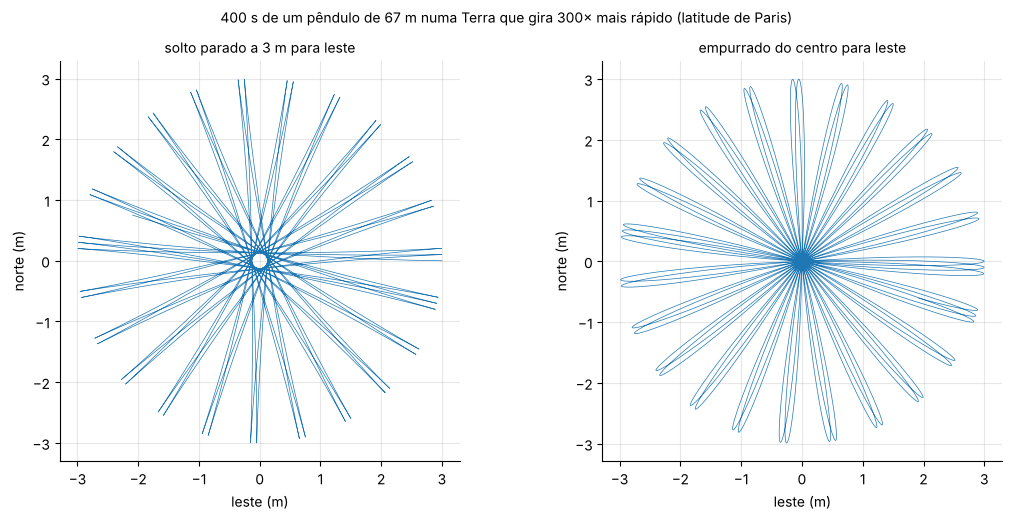

In [6]:
Oz_vis = 300 * OZ
fig, ax = plt.subplots(1, 2, figsize=(11, 5.2))
for a_, s_ini, tit in zip(ax, [np.array([3.0 + 0j, 0j]), np.array([0j, 3.0 * W0 + 0j])],
                          ["solto parado a 3 m para leste", "empurrado do centro para leste"]):
    s, zz = s_ini.copy(), []
    for i in range(int(400 / 0.05)):
        s = rk4(lambda t, y: f_foucault(t, y, Oz_vis), s, 0.05, 0.05); zz.append(s[0])
    zz = np.array(zz)
    a_.plot(zz.real, zz.imag, lw=0.5); a_.set_aspect("equal"); a_.set_title(tit, fontsize=10)
    a_.set_xlabel("leste (m)"); a_.set_ylabel("norte (m)")
fig.suptitle("400 s de um pêndulo de 67 m numa Terra que gira 300× mais rápido (latitude de Paris)", fontsize=10)
plt.tight_layout(); plt.show()

---

## 5. Integrar uma orientação: RK4 sai do círculo, RKMK não

Na etapa (d), Pepé anda pela arena e gira. A orientação dele é um complexo unitário $q=e^{i\psi}$ (para onde aponta o nariz), e um **giroscópio** mede a velocidade de giro $\omega(t)$. A equação da orientação é

$$\dot q=i\,\omega(t)\,q .$$

**Com o RK4 clássico**, o passo é $q\leftarrow q+\tfrac h6(\mathbf k_1+2\mathbf k_2+2\mathbf k_3+\mathbf k_4)$: uma **soma**. Com $\omega$ constante, o passo multiplica $q$ pelo polinômio do RK4, $R(i\omega h)=1+z+z^2/2+z^3/6+z^4/24$ com $z=i\omega h$, que só aproxima $e^{i\omega h}$. O módulo dele não é 1: a célula mostra que $\lvert R(ix)\rvert^2=1-x^6/72+x^8/576$. Cada passo **encolhe** $q$ um pouquinho, e os encolhimentos se acumulam.

**Com o RKMK** (Munthe-Kaas), o passo é uma **multiplicação**: calcula-se o incremento de ângulo $\Delta\psi$ com os mesmos estágios do RK4, mas em ângulo, e faz-se $q\leftarrow q\,e^{i\Delta\psi}$. O resultado tem módulo 1 por construção (a menos do arredondamento). Como $U(1)$ é comutativo, os colchetes de Lie do RKMK geral são zero, e o incremento é a regra de Simpson aplicada a $\omega(t)$:
$$\Delta\psi=\tfrac h6\big(\omega(t)+4\,\omega(t+h/2)+\omega(t+h)\big).$$

A célula compara os dois, com uma velocidade de giro que varia (Pepé virando para um lado e para o outro), por 10 minutos, com passo de 0,1 s. A orientação exata é $e^{i\psi(t)}$, com $\psi(t)=\int_0^t\omega$ calculada em fórmula fechada.

|R(ix)|² do RK4 = x**8/576 - x**6/72 + 1   (< 1 para x pequeno: o RK4 encolhe as rotações)
depois de 600 s com h = 0.1 s:
   RK4:  |q| − 1 = -2.71e-04;  erro de ângulo = 2.47e-05°
   RKMK: |q| − 1 = +2.22e-16;  erro de ângulo = 4.97e-06°
OK   RKMK fica no círculo (|q| = 1 até o arredondamento):  diferença máxima = 6.00e-15
OK   RK4 sai do círculo de modo mensurável:  diferença máxima = 0.00e+00


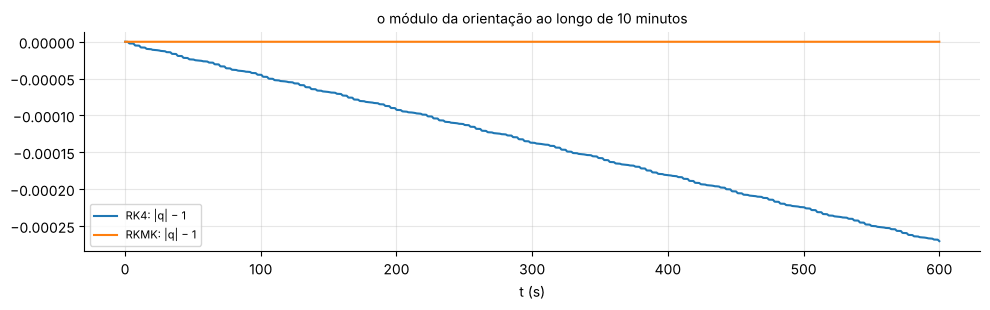

ordem no ângulo (60 s): RK4 3.88;  RKMK 4.07


In [7]:
omega = lambda t: 1.5 * np.sin(0.7 * t) + 0.3 * np.cos(2.3 * t)               # rad/s
psi_exato = lambda t: 1.5 / 0.7 * (1 - np.cos(0.7 * t)) + 0.3 / 2.3 * np.sin(2.3 * t)

def rk4_orientacao(T, h):
    q, mods = 1 + 0j, []
    f = lambda t, q: 1j * omega(t) * q
    for i in range(int(round(T / h))):
        t_ = i * h
        k1 = f(t_, q); k2 = f(t_ + h / 2, q + h / 2 * k1); k3 = f(t_ + h / 2, q + h / 2 * k2); k4 = f(t_ + h, q + h * k3)
        q = q + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
        mods.append(abs(q) - 1)
    return q, np.array(mods)

def rkmk_orientacao(T, h):
    q, mods = 1 + 0j, []
    for i in range(int(round(T / h))):
        t_ = i * h
        dpsi = h / 6 * (omega(t_) + 4 * omega(t_ + h / 2) + omega(t_ + h))
        q = q * np.exp(1j * dpsi)
        mods.append(abs(q) - 1)
    return q, np.array(mods)

xx = sp.Symbol("x", real=True)
R_rk4 = sum((sp.I * xx)**k / sp.factorial(k) for k in range(5))
print("|R(ix)|² do RK4 =", sp.expand(sp.re(R_rk4)**2 + sp.im(R_rk4)**2), "  (< 1 para x pequeno: o RK4 encolhe as rotações)")

T_or, h_or = 600.0, 0.1
q_rk, m_rk = rk4_orientacao(T_or, h_or)
q_mk, m_mk = rkmk_orientacao(T_or, h_or)
q_ex = np.exp(1j * psi_exato(T_or))
print(f"depois de {T_or:.0f} s com h = {h_or} s:")
print(f"   RK4:  |q| − 1 = {abs(q_rk) - 1:+.2e};  erro de ângulo = {np.degrees(abs(np.angle(q_rk / q_ex))):.2e}°")
print(f"   RKMK: |q| − 1 = {abs(q_mk) - 1:+.2e};  erro de ângulo = {np.degrees(abs(np.angle(q_mk / q_ex))):.2e}°")
confere("RKMK fica no círculo (|q| = 1 até o arredondamento)", np.max(np.abs(m_mk)), 0, tol=1e-12)
confere("RK4 sai do círculo de modo mensurável", abs(abs(q_rk) - 1) > 1e-6, True)

fig, ax = plt.subplots(figsize=(10, 3.2))
tt = np.arange(1, len(m_rk) + 1) * h_or
ax.plot(tt, m_rk, label="RK4: |q| − 1")
ax.plot(tt, m_mk, label="RKMK: |q| − 1")
ax.set_xlabel("t (s)"); ax.legend(fontsize=8); ax.set_title("o módulo da orientação ao longo de 10 minutos", fontsize=10)
plt.tight_layout(); plt.show()

hs = np.array([0.4, 0.2, 0.1, 0.05])
e_rk = [abs(np.angle(rk4_orientacao(60.0, h)[0] / np.exp(1j * psi_exato(60.0)))) for h in hs]
e_mk = [abs(np.angle(rkmk_orientacao(60.0, h)[0] / np.exp(1j * psi_exato(60.0)))) for h in hs]
print(f"ordem no ângulo (60 s): RK4 {np.polyfit(np.log(hs), np.log(e_rk), 1)[0]:.2f};  RKMK {np.polyfit(np.log(hs), np.log(e_mk), 1)[0]:.2f}")

**Leitura.**
- O RK4 **encolhe** a orientação: depois de 10 minutos com passo de 0,1 s, $\lvert q\rvert$ está $2{,}7\times10^{-4}$ abaixo de 1. O ângulo continua bom (erro de $2{,}5\times10^{-5}$ grau, ordem 4), mas $q$ já não é uma rotação: girar um vetor com ele o encurtaria. A figura mostra o módulo caindo de modo contínuo, mais depressa quando $\omega$ é grande (o encolhimento por passo é $x^6/144$, com $x=\omega h$).
- O RKMK fica no círculo até o arredondamento ($10^{-15}$), também com ordem 4 no ângulo, e com erro de ângulo cinco vezes menor neste exemplo.

No domínio III, com o ângulo como estado, o RK4 e o RKMK eram iguais (notebook III(c), seção 3). Aqui, com o complexo unitário como estado, deixam de ser: **a escolha de coordenadas decide se o integrador respeita o grupo**. Nos quaternions (domínio VI), o RK4 aplicado ao quaternion da atitude encolhe da mesma forma, e a prática corrente é renormalizar a cada passo ou, melhor, usar um integrador de Lie (exercício 3).

---

## 6. Espaço de estados para a etapa (d)

Na etapa (d), Pepé estima a própria orientação $q$ integrando um giroscópio que tem **viés** $b$ (um erro constante, ou quase, na velocidade medida: $\omega_{\text{medido}}=\omega+b+\text{ruído}$). A predição da orientação é o RKMK com um passo só:
$$\hat q\leftarrow\hat q\,e^{i(\omega_{\text{medido}}-\hat b)\Delta t}.$$

O filtro não guarda a covariância de $q$ (um complexo unitário não é um vetor), e sim a de um **erro de orientação** $\delta\psi$, definido por $q=\hat q\,e^{i\delta\psi}$: um ângulo pequeno, que vive num espaço vetorial (a reta). É o estado de erro do ESKF (notebook 5 da série Kalman), na sua forma mais simples. O erro e o viés evoluem como

$$\dot{\delta\psi}=-\delta b+n_\omega,\qquad\dot{\delta b}=n_b,$$

com $n_\omega$ o ruído branco do giroscópio e $n_b$ o passeio aleatório do viés. A célula discretiza esse modelo com o método de Van Loan (notebook I(c)). Com um giroscópio de ruído $0{,}01$ rad/s/$\sqrt{\text{Hz}}$ e viés que passeia $5\times10^{-4}$ rad/s/$\sqrt{\text{s}}$, e $\Delta t=0{,}05$ s:

In [8]:
def discretiza(A, B, dt, q):
    n = A.shape[0]
    V = np.zeros((2 * n, 2 * n)); V[:n, :n] = -A; V[:n, n:] = B @ np.diag(q) @ B.T; V[n:, n:] = A.T
    W = expm(V * dt); F = expm(A * dt)
    Q = F @ W[:n, n:]
    return F, 0.5 * (Q + Q.T)

SIG_GIRO, SIG_VIES, DT = 0.01, 5e-4, 0.05
A_or = np.array([[0.0, -1.0], [0.0, 0.0]])
F_or, Q_or = discretiza(A_or, np.eye(2), DT, [SIG_GIRO**2, SIG_VIES**2])
print("F =\n", F_or, "\nQ =\n", Q_or)
Q_formula = np.array([[SIG_GIRO**2 * DT + SIG_VIES**2 * DT**3 / 3, -SIG_VIES**2 * DT**2 / 2],
                      [-SIG_VIES**2 * DT**2 / 2, SIG_VIES**2 * DT]])
confere("Q de Van Loan = fórmula fechada", Q_or, Q_formula, tol=1e-20)

# quanto o ângulo erra sem correção, em 60 s, só por causa do viés não estimado
print(f"\num viés de 0,02 rad/s não corrigido gira a estimativa de {np.degrees(0.02 * 60):.0f}° em um minuto")

F =
 [[ 1.   -0.05]
 [ 0.    1.  ]] 
Q =
 [[ 0.000005 -0.      ]
 [-0.        0.      ]]
OK   Q de Van Loan = fórmula fechada:  diferença máxima = 8.47e-22

um viés de 0,02 rad/s não corrigido gira a estimativa de 69° em um minuto


**Leitura.** O ruído do giroscópio sozinho faria o erro de ângulo crescer como um passeio aleatório: depois de um minuto, $0{,}01\sqrt{60}\approx0{,}08$ rad, uns 4°. O viés é muito pior: cresce **linearmente**, e um viés modesto de 0,02 rad/s dá quase 70° em um minuto. É por isso que, na etapa (d), Pepé precisa de alguma referência externa (faróis em posições conhecidas) para estimar o viés, e não só a orientação.

---

## 7. Exercícios

1. **Foucault no Brasil.** Repita a seção 4 para a latitude de 20° S. Meça o ângulo do plano depois de uma hora e confira o sentido (anti-horário) e o valor.
2. **A força centrífuga.** Inclua o termo $+\Omega_z^2z$ (seção 2) na equação de Foucault. Quanto ele muda a frequência do pêndulo? E a precessão?
3. **Renormalizar o RK4.** Na seção 5, renormalize $q$ depois de cada passo do RK4. O erro de ângulo muda? O RK4 renormalizado é tão bom quanto o RKMK?
4. **RKMK com ω medido.** Na prática, o giroscópio dá $\omega$ só nos instantes de amostragem, e não em $t+h/2$. Reescreva o RKMK usando só amostras ($\omega_k$ e $\omega_{k+1}$, com a regra do trapézio). Qual é a ordem agora?
5. **Coriolis numa bola de tênis de mesa.** Use a equação da seção 2 para estimar o desvio lateral de uma bola lançada a 10 m/s por 2,74 m (o comprimento da mesa) em Paris. Compare com o efeito do giro da bola (Magnus), que chega a vários centímetros.